In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import ttest_ind
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

# Load dataset
df = pd.read_csv("top 120 best-selling mobile phones.csv")

In [2]:
# Display first five rows
print(df.head())

   Rank Manufacturer                Model  Form Factor  Smartphone?  Year  \
0     1        Nokia                 1100          Bar        False  2003   
1     2        Nokia                 1110          Bar        False  2005   
2     3        Apple    iPhone 6 & 6 Plus  Touchscreen         True  2014   
3     4        Nokia           105 Series          Bar        False  2013   
4     5        Apple  iPhone 6S & 6S Plus  Touchscreen         True  2015   

   Units Sold (million )  
0                  250.0  
1                  247.5  
2                  222.4  
3                  200.0  
4                  174.1  


Exploratory Data Analysis (EDA)

In [3]:
# Dataset information
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Rank                   120 non-null    int64  
 1   Manufacturer           120 non-null    object 
 2   Model                  120 non-null    object 
 3   Form Factor            120 non-null    object 
 4   Smartphone?            120 non-null    bool   
 5   Year                   120 non-null    int64  
 6   Units Sold (million )  120 non-null    float64
dtypes: bool(1), float64(1), int64(2), object(3)
memory usage: 5.9+ KB
None


In [4]:
# Check missing values
print(df.isnull().sum())

Rank                     0
Manufacturer             0
Model                    0
Form Factor              0
Smartphone?              0
Year                     0
Units Sold (million )    0
dtype: int64


In [5]:
# Summary statistics for numerical columns
print(df.describe())

             Rank         Year  Units Sold (million )
count  120.000000   120.000000             120.000000
mean    60.500000  2012.758333              48.050000
std     34.785054     6.590030              58.044835
min      1.000000  1996.000000               2.000000
25%     30.750000  2007.000000              10.000000
50%     60.500000  2013.000000              22.050000
75%     90.250000  2019.000000              60.000000
max    120.000000  2024.000000             250.000000


Histogram of units sold

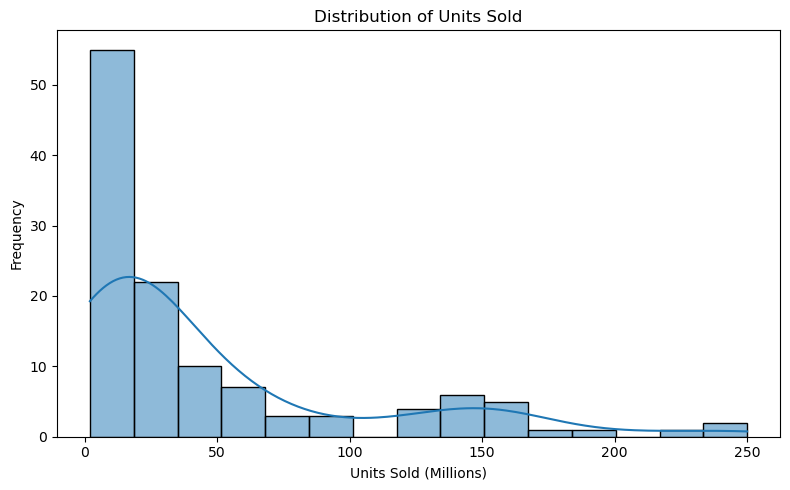

In [6]:
plt.figure(figsize=(8, 5))

sns.histplot(df["Units Sold (million )"], bins=15, kde=True)

plt.title("Distribution of Units Sold")
plt.xlabel("Units Sold (Millions)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

Trend of units sold over the years

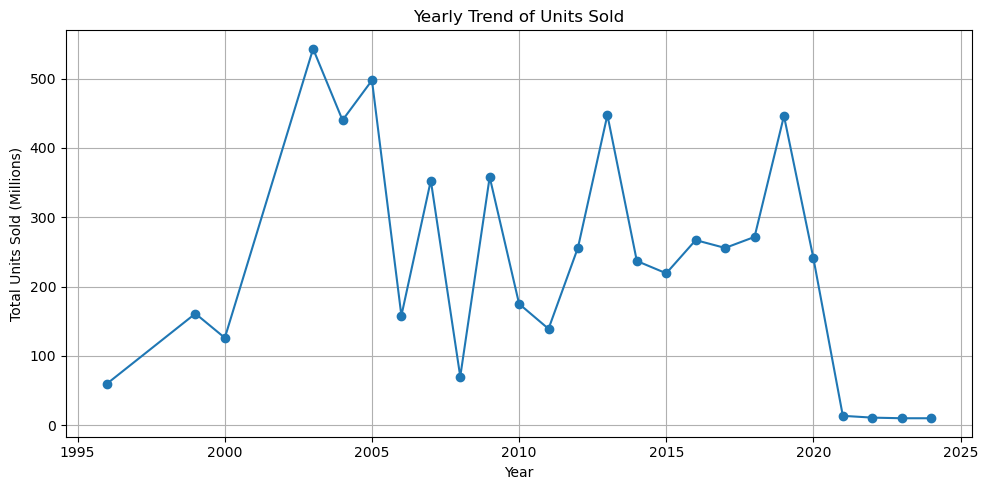

In [7]:
# Calculate total units sold per year
yearly_sales = df.groupby("Year")["Units Sold (million )"].sum()

plt.figure(figsize=(10, 5))

plt.plot(yearly_sales.index, yearly_sales.values, marker="o")

plt.title("Yearly Trend of Units Sold")
plt.xlabel("Year")
plt.ylabel("Total Units Sold (Millions)")
plt.grid(True)

plt.tight_layout()
plt.show()

Statistical Analysis

In [8]:
# Separate smartphone and non-smartphone sales
smartphones = df[df["Smartphone?"] == True]["Units Sold (million )"]
non_smartphones = df[df["Smartphone?"] == False]["Units Sold (million )"]

# Perform independent two-sample Welch's t-test
t_stat, p_value = ttest_ind(
    smartphones,
    non_smartphones,
    equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("There is a statistically significant difference in units sold.")
else:
    print("There is no statistically significant difference in units sold.")

T-statistic: -2.961342609890579
P-value: 0.00470766594289731
There is a statistically significant difference in units sold.


Correlation matrix and heatmap

                           Rank      Year  Units Sold (million )
Rank                   1.000000  0.380899               -0.83691
Year                   0.380899  1.000000               -0.31453
Units Sold (million ) -0.836910 -0.314530                1.00000


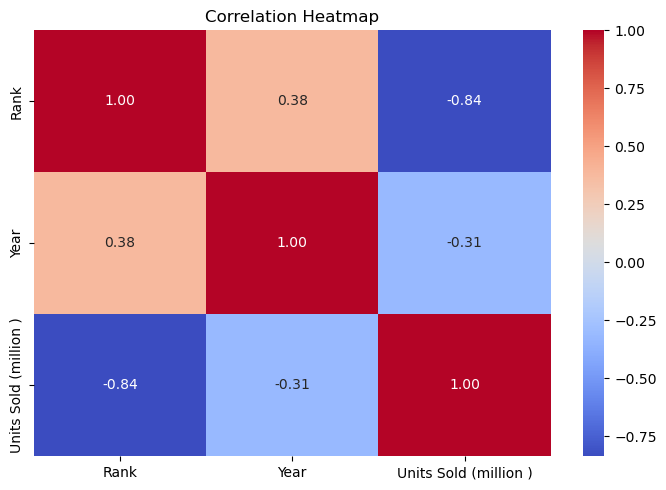

In [9]:
# Select numerical columns for correlation
numeric_data = df[
    ["Rank", "Year", "Units Sold (million )"]
]

# Calculate correlation matrix
correlation = numeric_data.corr()

print(correlation)

# Visualize correlation
plt.figure(figsize=(7, 5))

sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

Data Manipulation with Pandas

In [10]:
#Total units sold by manufacturer
manufacturer_sales = df.groupby("Manufacturer")[
    "Units Sold (million )"
].sum().sort_values(ascending=False)

print(manufacturer_sales)

Manufacturer
Nokia                       2374.5
Apple                       1669.3
Samsung                      994.5
Motorola                     323.0
Huawei                       113.8
Xiaomi                        99.1
LG                            92.0
Sony Ericsson                 45.0
Oppo                          16.7
HTC                           16.0
Research in Motion (RIM)      15.0
LeTV                           3.0
Google                         2.1
Palm                           2.0
Name: Units Sold (million ), dtype: float64


Top 5 manufacturers

In [11]:
top_5_manufacturers = manufacturer_sales.head(5)

print(top_5_manufacturers)

Manufacturer
Nokia       2374.5
Apple       1669.3
Samsung      994.5
Motorola     323.0
Huawei       113.8
Name: Units Sold (million ), dtype: float64


Manufacturer sales by year

In [12]:
pivot_table = pd.pivot_table(
    df,
    values="Units Sold (million )",
    index="Manufacturer",
    columns="Year",
    aggfunc="sum",
    fill_value=0
)

print(pivot_table)

Year                      1996   1999   2000   2003   2004   2005  2006  \
Manufacturer                                                              
Apple                      0.0    0.0    0.0    0.0    0.0    0.0   0.0   
Google                     0.0    0.0    0.0    0.0    0.0    0.0   0.0   
HTC                        0.0    0.0    0.0    0.0    0.0    0.0   0.0   
Huawei                     0.0    0.0    0.0    0.0    0.0    0.0   0.0   
LG                         0.0    0.0    0.0    0.0    0.0    0.0  21.0   
LeTV                       0.0    0.0    0.0    0.0    0.0    0.0   0.0   
Motorola                  60.0    0.0    0.0   60.0  130.0   60.0   0.0   
Nokia                      0.0  161.0  126.0  473.0  295.0  422.5  77.0   
Oppo                       0.0    0.0    0.0    0.0    0.0    0.0   0.0   
Palm                       0.0    0.0    0.0    0.0    0.0    0.0   0.0   
Research in Motion (RIM)   0.0    0.0    0.0    0.0    0.0    0.0  15.0   
Samsung                  

Data Visualization

Bar chart of the top 10 best-selling phone models

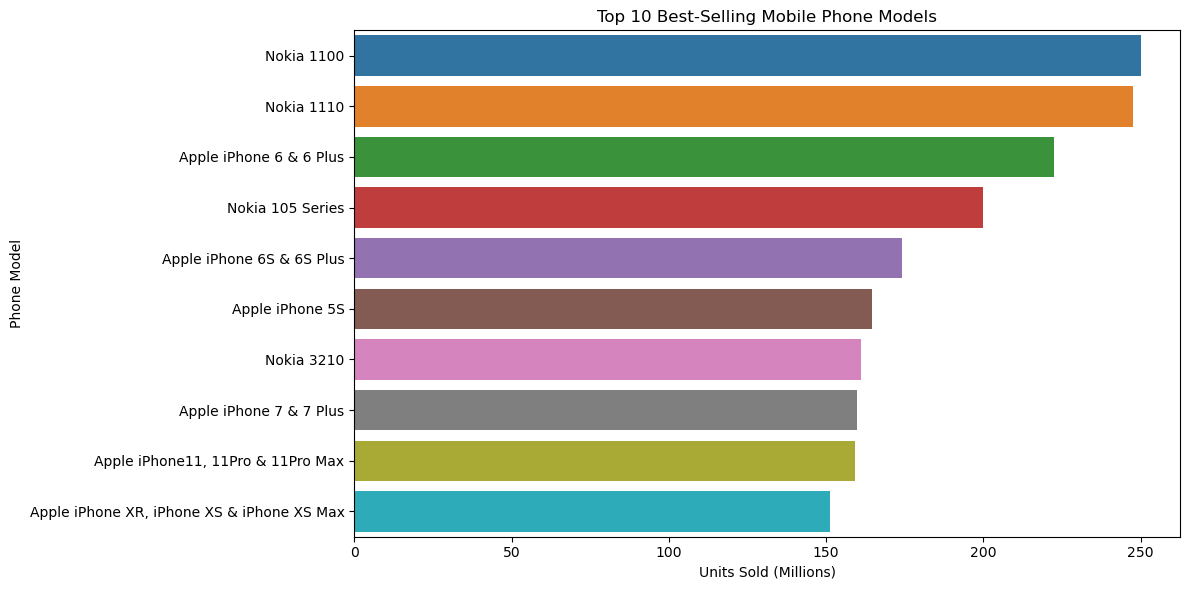

In [13]:
# Select top 10 models by units sold
top_10_models = df.nlargest(10, "Units Sold (million )").copy()

# Add manufacturer to model name for clarity
top_10_models["Phone"] = (
    top_10_models["Manufacturer"] + " " + top_10_models["Model"]
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_10_models,
    x="Units Sold (million )",
    y="Phone",
    hue="Phone",
    legend=False
)

plt.title("Top 10 Best-Selling Mobile Phone Models")
plt.xlabel("Units Sold (Millions)")
plt.ylabel("Phone Model")

plt.tight_layout()
plt.show()

Smartphones vs. non-smartphones

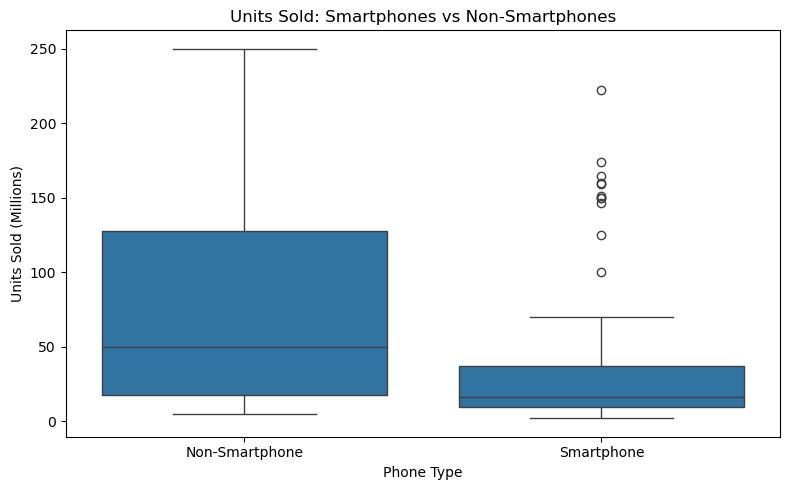

In [14]:
# Create readable category labels
df["Phone Type"] = df["Smartphone?"].map({
    True: "Smartphone",
    False: "Non-Smartphone"
})

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Phone Type",
    y="Units Sold (million )"
)

plt.title("Units Sold: Smartphones vs Non-Smartphones")
plt.xlabel("Phone Type")
plt.ylabel("Units Sold (Millions)")

plt.tight_layout()
plt.show()

Machine Learning — Linear Regression

In [15]:
from sklearn.model_selection import train_test_split

# Select input and output variables
X = df[["Year"]]
y = df["Units Sold (million )"]

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create and train the model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict units sold
y_pred = model.predict(X_test)

# Evaluate the model
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)

print("R-squared:", r2)
print("Mean Squared Error:", mse)
print("Regression Coefficient:", model.coef_[0])
print("Intercept:", model.intercept_)

R-squared: 0.16169979253184785
Mean Squared Error: 3460.2428594265875
Regression Coefficient: -2.203274920435347
Intercept: 4482.032680444778


Visualize the regression line

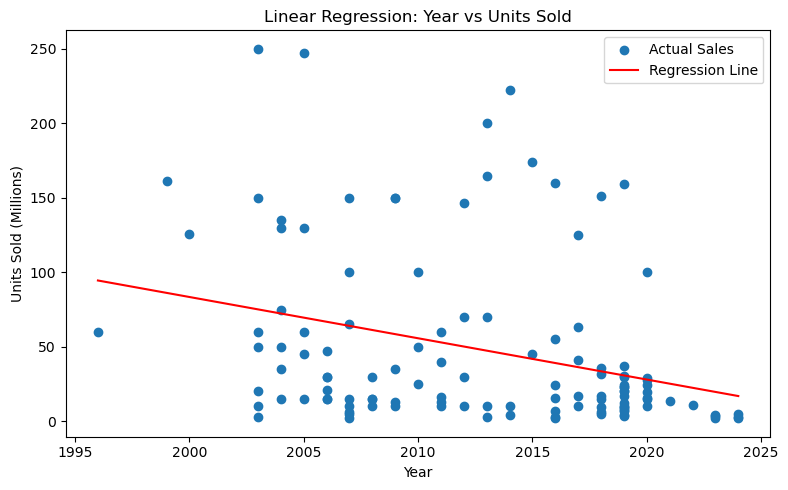

In [16]:
# Fit the model using all observations
model.fit(X, y)

# Sort years before plotting
plot_data = X.copy()
plot_data["Predicted Sales"] = model.predict(X)
plot_data = plot_data.sort_values("Year")

# Create the chart
plt.figure(figsize=(8, 5))

plt.scatter(X["Year"], y, label="Actual Sales")

plt.plot(
    plot_data["Year"],
    plot_data["Predicted Sales"],
    color="red",
    label="Regression Line"
)

plt.title("Linear Regression: Year vs Units Sold")
plt.xlabel("Year")
plt.ylabel("Units Sold (Millions)")
plt.legend()
plt.tight_layout()
plt.show()
